# 02 · Diseño muestral y validez interna

**Objetivo.** Establecer **cómo se asignó la oferta** (aleatoria o no, simple o estratificada, individual o por conglomerados) y verificar las condiciones que dan validez interna al experimento: balance de las características previas, cumplimiento y faltantes en los resultados.

**Justificación.** El método de estimación y la forma de calcular los errores estándar dependen del diseño:

| Si el diseño es... | Entonces... |
|---|---|
| Aleatorio simple | Basta una diferencia de medias |
| Estratificado (por centro) | Se incluyen efectos fijos de estrato y la inferencia por aleatorización permuta dentro de cada estrato |
| Por conglomerados (centros enteros) | El número efectivo de observaciones es el número de centros (5) y se agrupan los errores |
| Con cumplimiento imperfecto | Hay que distinguir ITT y LATE |
| Con atrición diferencial | El ITT de casos completos puede estar sesgado |

La documentación del sorteo no está disponible, así que el diseño se **infiere de los datos** y se declara como supuesto.

> **En sencillo — validez interna:** que la diferencia entre grupos se deba a la intervención y no a otra cosa. Un sorteo limpio la garantiza *al inicio*; este notebook revisa que nada la haya roto después (desbalance, uso cruzado, pérdida de datos).
>
> **Estratificar** es sortear por separado dentro de subgrupos (aquí, cada centro), para asegurar que todos los centros tengan sorteadas y no sorteadas en la misma proporción [1]. Un **conglomerado** sería sortear centros enteros en lugar de madres.

### Preparación del entorno

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Rutas relativas a la raíz del repositorio
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "caso05_cuidado_infantil.dta"
PROCESSED = ROOT / "data" / "processed" / "caso05_analitico.csv"

# Roles de las variables (definidos en 00_planteamiento_teoria_cambio)
ID, CENTER = "hogar_id", "centro_id"
Z = "oferta_sorteo"            # asignación aleatoria (instrumento)
D = "uso_horario_ampliado"     # tratamiento recibido (endógeno)
BASELINE = [
    "edad_madre", "numero_hijos", "edad_menor", "educ_madre", "madre_sola",
    "traslado_min", "red_cuidado", "empleo_pre", "horas_pre", "ingreso_pre",
]
OUTCOMES = ["empleo_post", "horas_post", "ingreso_post_c", "bienestar_post"]
ALPHA, SEED = 0.05, 2026

# Estilo gráfico: oferta = azul, sin oferta = naranja; grilla recesiva
COLORS = {0: "#eb6834", 1: "#2a78d6"}
LABELS = {0: "Sin oferta (Z=0)", 1: "Con oferta (Z=1)"}
NEUTRAL = "#8a8984"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e6e6e3", "figure.dpi": 110, "axes.titleweight": "bold",
})

In [2]:
# Base analítica generada en 01_datos_auditoria_construccion.ipynb
if not PROCESSED.exists():
    raise FileNotFoundError(
        "No existe la base analítica. Ejecute primero 01_datos_auditoria_construccion.ipynb"
    )
df = pd.read_csv(PROCESSED)
print(f"Base analítica: {df.shape[0]} filas x {df.shape[1]} columnas")

Base analítica: 1500 filas x 28 columnas


In [3]:
import statsmodels.formula.api as smf
from scipy import stats

## 2.1 Unidad de asignación: ¿individual o por conglomerados?

**Fundamento metodológico.** En un diseño por conglomerados, todas las madres de un centro tendrían el mismo valor de $Z$, y la proporción sorteada por centro sería 0 o 1. Si $Z$ varía dentro de cada centro, la asignación es **individual**.

In [4]:
por_centro = (
    df.groupby(CENTER)
    .agg(n=(Z, "size"), sorteadas=(Z, "sum"), prop_sorteadas=(Z, "mean"))
    .assign(no_sorteadas=lambda t: t["n"] - t["sorteadas"],
            dif_vs_mitad=lambda t: t["sorteadas"] - t["n"] / 2)
)
display(por_centro)

,n,sorteadas,prop_sorteadas,no_sorteadas,dif_vs_mitad
centro_id,,,,,
1,301,150,0.498,151,-0.500
2,303,151,0.498,152,-0.500
3,292,146,0.500,146,0.000
4,314,157,0.500,157,0.000
5,290,145,0.500,145,0.000


**Interpretación.** En los 5 centros hay madres sorteadas y no sorteadas, y la proporción sorteada es prácticamente 50 % en todos. La asignación es **individual dentro de centros**, no por conglomerados. Así, la unidad de análisis coincide con la unidad de asignación y la inferencia se hace a nivel individual.

## 2.2 Mecanismo: ¿sorteo simple o estratificado por centro?

**Fundamento metodológico.** Hay dos mecanismos plausibles:

- **Bernoulli (sorteo independiente, $p=0.5$):** el número de sorteadas por centro sería aleatorio, $S_c \sim \text{Binomial}(n_c, 0.5)$, y podría alejarse de $n_c/2$.
- **Completo por estrato (bloques):** se sortea un número fijo, $\lfloor n_c/2 \rfloor$ o $\lceil n_c/2 \rceil$, en cada centro.

> **En sencillo:** con Bernoulli es como lanzar una moneda por cada madre: en un centro de 300 podrían salir 140 o 160 sorteadas. Con bloques es como meter 150 papelitos de "sí" y 150 de "no" en una urna por centro: siempre salen exactamente la mitad. La fórmula $\text{Binomial}(n_c, 0.5)$ da la probabilidad de cada resultado posible al lanzar $n_c$ monedas.

Se calcula la probabilidad de observar, bajo Bernoulli, una división **exactamente a la mitad** en los 5 centros. Si esa probabilidad es despreciable, los datos son mucho más compatibles con un sorteo estratificado de cupos fijos.

In [5]:
def prob_division_exacta(n):
    # P(S = floor(n/2) o S = ceil(n/2)) bajo Binomial(n, 0.5)
    valores = {int(np.floor(n / 2)), int(np.ceil(n / 2))}
    return sum(stats.binom.pmf(k, n, 0.5) for k in valores)

por_centro["P_mitad_bajo_Bernoulli"] = por_centro["n"].apply(prob_division_exacta)
p_conjunta = por_centro["P_mitad_bajo_Bernoulli"].prod()
display(por_centro[["n", "sorteadas", "P_mitad_bajo_Bernoulli"]])
print(f"P(división exacta en los 5 centros | Bernoulli) = {p_conjunta:.2e}")

,n,sorteadas,P_mitad_bajo_Bernoulli
centro_id,,,
1,301,150,0.092
2,303,151,0.091
3,292,146,0.047
4,314,157,0.045
5,290,145,0.047


P(división exacta en los 5 centros | Bernoulli) = 8.24e-07


**Interpretación.** Bajo un sorteo Bernoulli, la probabilidad de que los 5 centros queden divididos exactamente a la mitad es del orden de $10^{-6}$. Los datos son abrumadoramente más compatibles con un **sorteo completo estratificado por centro** (aleatorización por bloques): en cada centro se sortearon $n_c/2$ vacantes.

**Implicancias**

1. La probabilidad de ser sorteada es la misma (≈ 0.5) en todos los centros: **no hacen falta ponderaciones** y la diferencia de medias simple es insesgada. Aun así, los **efectos fijos de centro** respetan el diseño y suelen mejorar la precisión.
2. La inferencia por aleatorización (04) debe **permutar $Z$ dentro de cada centro, manteniendo fijo el número de sorteadas**.
3. Esto es una inferencia a partir de los datos, no una prueba documental. Si el sorteo real fue otro, la permutación debe reflejarlo.

## 2.3 Balance de características previas

**Objetivo.** Verificar si los grupos con y sin oferta son comparables antes de la intervención.

**Fundamento metodológico.** Si el sorteo fue aleatorio, las diferencias en variables previas deben ser pequeñas y compatibles con el azar. Se reportan tres métricas complementarias:

- **Diferencia estandarizada de medias (SMD):** $\dfrac{\bar X_1 - \bar X_0}{\sqrt{(s_1^2+s_0^2)/2}}$. No depende del tamaño de muestra. Por convención, $|SMD| < 0.1$ indica buen balance [2].

  > **En sencillo:** la SMD expresa la diferencia entre grupos en "desviaciones estándar" y no en las unidades de cada variable, para poder comparar edad (años), ingreso (u.m.) o empleo (%) en una misma escala. Una SMD de 0.1 significa que las medias difieren en una décima de la dispersión típica de esa variable: una diferencia pequeña.
- **Razón de varianzas** $s_1^2/s_0^2$: compara la dispersión, no solo la media (dos grupos pueden tener la misma media pero uno más disperso). Un valor entre 0.8 y 1.25 es aceptable.
- **Prueba $t$ dentro de centros:** coeficiente de $Z$ en $X_k = \alpha + \beta Z + \delta_c + \varepsilon$, con errores HC3, para respetar el diseño.

> **En sencillo — valor $p$:** es la probabilidad de ver una diferencia al menos tan grande como la observada *si en realidad no hubiera diferencia*. Un $p$ alto (por ejemplo 0.7) dice "esta diferencia es perfectamente esperable por azar". Un $p$ bajo (< 0.05) dice "sería raro verla solo por azar".
>
> **Efectos fijos de centro ($\delta_c$):** una constante distinta para cada centro. Equivale a comparar sorteadas y no sorteadas *dentro de cada centro* y promediar, de modo que las diferencias entre centros no contaminan la comparación.
>
> **Errores HC3:** una forma de calcular el margen de error que no supone que todos los grupos tienen la misma variabilidad. Se detalla en 04.

Advertencia: con 10 variables se esperan en promedio 0.5 valores $p < 0.05$ por puro azar, y la probabilidad de ver al menos uno es cercana a 40 %. Por eso se agrega una **prueba conjunta** (2.4).

In [6]:
def tabla_balance(data, variables, grupo, estrato=None):
    # Balance por variable: medias, SMD, razón de varianzas y p-valor (con efectos fijos de estrato si se indica)
    filas = []
    for v in variables:
        x1, x0 = data.loc[data[grupo] == 1, v], data.loc[data[grupo] == 0, v]
        sd = np.sqrt((x1.var() + x0.var()) / 2)
        formula = f"{v} ~ {grupo}" + (f" + C({estrato})" if estrato else "")
        p = smf.ols(formula, data=data).fit(cov_type="HC3").pvalues[grupo]
        filas.append({"variable": v, "media_sin_oferta": x0.mean(), "media_con_oferta": x1.mean(),
                      "diferencia": x1.mean() - x0.mean(), "smd": (x1.mean() - x0.mean()) / sd,
                      "razon_var": x1.var() / x0.var(), "p_valor": p})
    return pd.DataFrame(filas).set_index("variable")

balance = tabla_balance(df, BASELINE, Z, CENTER)
display(balance)

,media_sin_oferta,media_con_oferta,diferencia,smd,razon_var,p_valor
variable,,,,,,
edad_madre,29.397,29.419,0.022,0.004,0.905,0.939
numero_hijos,1.626,1.656,0.030,0.037,1.094,0.469
edad_menor,2.567,2.529,-0.039,-0.036,0.960,0.487
educ_madre,11.625,11.574,-0.050,-0.017,0.964,0.741
madre_sola,0.309,0.299,-0.010,-0.021,0.982,0.678
traslado_min,41.598,42.032,0.434,0.025,0.874,0.628
red_cuidado,0.435,0.441,0.005,0.010,1.003,0.837
empleo_pre,0.466,0.473,0.007,0.013,1.002,0.796
horas_pre,15.766,15.654,-0.112,-0.006,0.974,0.905


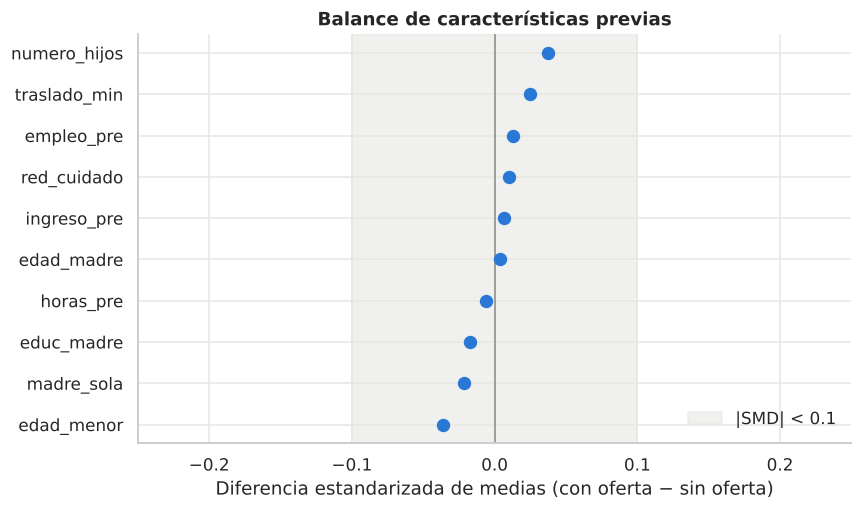

In [7]:
# Gráfico de balance (love plot): |SMD| por variable con umbral 0.1
b = balance.sort_values("smd")
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.axvspan(-0.1, 0.1, color="#e6e6e3", alpha=0.6, label="|SMD| < 0.1")
ax.axvline(0, color=NEUTRAL, lw=1)
ax.scatter(b["smd"], b.index, s=60, color=COLORS[1], zorder=3)
ax.set_xlim(-0.25, 0.25)
ax.set_xlabel("Diferencia estandarizada de medias (con oferta − sin oferta)")
ax.set_title("Balance de características previas")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

**Interpretación**

- Las 10 características tienen $|SMD| \le 0.04$, muy por debajo del umbral de 0.1. Las razones de varianzas están entre 0.87 y 1.09, así que tampoco hay diferencias de dispersión.
- Ningún valor $p$ individual es menor que 0.4. Las diferencias en medias son despreciables también en términos sustantivos: 0.7 pp en empleo previo, 5 unidades monetarias (u.m.) en ingreso previo, 0.4 minutos de traslado.
- En particular, están balanceadas las **líneas de base de los resultados** (`empleo_pre`, `horas_pre`, `ingreso_pre`), que son las que más pesan sobre el sesgo potencial.

## 2.4 Prueba conjunta de aleatorización

**Fundamento metodológico.** Se estima $Z_i = \alpha + X_i'\gamma + \delta_c + u_i$ y se contrasta $H_0: \gamma = 0$ (las características previas no predicen la asignación). Se calcula el valor $p$ de dos formas:

1. **Asintótico:** prueba de Wald con errores HC3.
2. **Por aleatorización** [3, 4]: se permuta $Z$ dentro de cada centro (el mecanismo inferido en 2.2), se recalcula el estadístico 2 000 veces y se compara el observado con esa distribución.

> **En sencillo — prueba de Wald:** pregunta si *todas* las covariables juntas ayudan a predecir quién fue sorteada. Es mejor que mirar 10 valores $p$ por separado, porque con 10 pruebas alguna puede salir "significativa" por azar. Es **asintótica**: su fórmula es una aproximación que funciona bien con muestras grandes.
>
> **Prueba por aleatorización (permutación):** se "vuelve a sortear" miles de veces en la computadora, con las mismas reglas del sorteo real, y se mira qué tan raro es el resultado observado entre todos esos sorteos imaginarios. No necesita aproximaciones: su validez viene del propio mecanismo del sorteo. Con 2 000 réplicas el valor $p$ tiene un pequeño error de simulación (±0.01 aproximadamente).

In [8]:
formula_conjunta = f"{Z} ~ " + " + ".join(BASELINE) + f" + C({CENTER})"
hipotesis = ", ".join(f"{v} = 0" for v in BASELINE)
modelo_conj = smf.ols(formula_conjunta, data=df).fit(cov_type="HC3")
wald = modelo_conj.wald_test(hipotesis, scalar=True)
print(f"Wald (HC3): chi2({len(BASELINE)}) = {wald.statistic:.2f}, p = {wald.pvalue:.3f}")

def permutar_en_estratos(z, estratos, rng):
    # Permuta z dentro de cada estrato, conservando el número de sorteadas
    z_perm = z.copy()
    for idx in estratos:
        z_perm[idx] = rng.permutation(z[idx])
    return z_perm

# F de MCO (homocedástica) como estadístico de la prueba por permutación (más rápido)
def estadistico_f(z_vec):
    datos = df.assign(**{Z: z_vec})
    return smf.ols(formula_conjunta, data=datos).fit().f_test(hipotesis).fvalue

rng = np.random.default_rng(SEED)
estratos = list(df.groupby(CENTER).indices.values())
z_obs = df[Z].to_numpy()
f_obs = estadistico_f(z_obs)
f_perm = np.array([estadistico_f(permutar_en_estratos(z_obs, estratos, rng)) for _ in range(2000)])
p_ri = (1 + (f_perm >= f_obs).sum()) / (len(f_perm) + 1)
print(f"F observado = {f_obs:.3f}; p por aleatorización = {p_ri:.3f}")

Wald (HC3): chi2(10) = 2.78, p = 0.986


F observado = 0.281; p por aleatorización = 0.986


**Interpretación.** Las 10 características, en conjunto, **no predicen la asignación**: $p = 0.986$ tanto con la prueba asintótica como con la prueba por aleatorización. No hay evidencia contra la hipótesis de que el sorteo fue aleatorio.

Un valor $p$ tan alto no "prueba" la aleatorización, pero es lo esperable si se cumple. Un sorteo manipulado, por ejemplo uno que favoreciera a madres con empleo previo, habría producido un estadístico en la cola de la distribución.

## 2.5 Balance dentro de cada centro

Como el sorteo fue por estrato, también se revisa el balance dentro de cada centro. Un desbalance concentrado en un centro podría indicar un problema local de implementación.

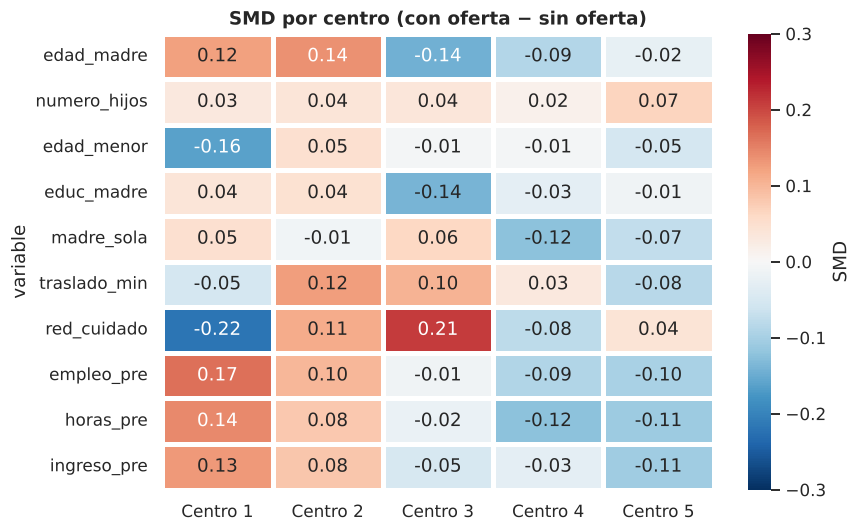

Celdas con |SMD| > 0.1: 17 de 50 (esperadas por azar ≈ 19.3)


In [9]:
smd_centros = pd.DataFrame({
    c: tabla_balance(sub, BASELINE, Z)["smd"] for c, sub in df.groupby(CENTER)
})
smd_centros.columns = [f"Centro {c}" for c in smd_centros.columns]

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(smd_centros, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.3, vmax=0.3,
            linewidths=2, linecolor="white", cbar_kws={"label": "SMD"}, ax=ax)
ax.set_title("SMD por centro (con oferta − sin oferta)")
plt.tight_layout(); plt.show()
# Celdas esperadas con |SMD| > 0.1 por azar: SE(SMD) ≈ sqrt(1/n1 + 1/n0) en cada centro
esperadas = sum(
    2 * (1 - stats.norm.cdf(0.1 / np.sqrt(1 / (sub[Z] == 1).sum() + 1 / (sub[Z] == 0).sum())))
    for _, sub in df.groupby(CENTER)
) * len(BASELINE)
print(f"Celdas con |SMD| > 0.1: {int((smd_centros.abs() > 0.1).sum().sum())} de {smd_centros.size} "
      f"(esperadas por azar ≈ {esperadas:.1f})")

**Interpretación**

- Dentro de los centros, las SMD son mayores que en el agregado (hasta ±0.22) y 17 de 50 celdas superan 0.1. **Es lo esperable por azar:** con unas 150 madres por grupo y centro, el error estándar de la SMD es ≈ 0.115, y se esperan unas 19 celdas por encima de 0.1. El número observado está en línea con eso.
- No aparece un patrón sistemático. El centro 1 tiene ligeramente más empleo e ingreso previos entre las sorteadas (SMD ≈ 0.13-0.17), pero el centro 5 muestra lo contrario. En el agregado se compensan.
- **Decisión:** el desbalance por centro no amenaza la validez interna, pero justifica **ajustar por las líneas de base** en la especificación principal. Esto corrige pequeñas diferencias aleatorias y mejora la precisión.

## 2.6 Cumplimiento

**Fundamento metodológico.** Bajo **monotonicidad** (nadie usa el servicio *porque no* fue sorteada), la población se divide en tres tipos no observables individualmente, cuyas proporciones sí se pueden calcular [5]:

| Tipo | $D(0)$ | $D(1)$ | Proporción identificada |
|---|---|---|---|
| Siempre usuarias (*always-takers*) | 1 | 1 | $P(D=1 \mid Z=0)$ |
| Nunca usuarias (*never-takers*) | 0 | 0 | $P(D=0 \mid Z=1)$ |
| Cumplidoras (*compliers*) | 0 | 1 | $P(D=1\mid Z=1) - P(D=1\mid Z=0)$ |

El LATE es el efecto **para las cumplidoras**. Su proporción también es la **primera etapa**, es decir, el denominador del estimador de Wald.

> **En sencillo:** no se puede saber si una madre concreta es cumplidora (solo se ve una de sus dos situaciones posibles), pero sí cuántas hay. Si el 20 % de las no sorteadas usa el servicio igual, ese 20 % son "siempre usuarias", y se supone que también hay un 20 % de ellas entre las sorteadas. Si el 82.6 % de las sorteadas lo usa, el exceso (82.6 − 20.2 ≈ 62 %) son las que lo usan *gracias* al sorteo: las cumplidoras.

In [10]:
tabla_cumpl = pd.crosstab(df[Z].map(LABELS), df[D].map({0: "No usa", 1: "Usa"}), margins=True, margins_name="Total")
display(tabla_cumpl)

p_d_z1 = df.loc[df[Z] == 1, D].mean()
p_d_z0 = df.loc[df[Z] == 0, D].mean()
tipos = pd.Series({
    "Siempre usuarias  P(D=1|Z=0)": p_d_z0,
    "Nunca usuarias    P(D=0|Z=1)": 1 - p_d_z1,
    "Cumplidoras       P(D=1|Z=1) - P(D=1|Z=0)": p_d_z1 - p_d_z0,
}).mul(100)
display(tipos.to_frame("% de la población"))

primera_etapa_centros = df.groupby([CENTER, Z])[D].mean().unstack().rename(columns=LABELS)
primera_etapa_centros["cumplidoras (pp)"] = (primera_etapa_centros.iloc[:, 1] - primera_etapa_centros.iloc[:, 0]) * 100
primera_etapa_centros["siempre usuarias (%)"] = 100 * primera_etapa_centros.iloc[:, 0]
primera_etapa_centros["nunca usuarias (%)"] = 100 * (1 - primera_etapa_centros.iloc[:, 1])
display(primera_etapa_centros)
r = primera_etapa_centros[["siempre usuarias (%)", "nunca usuarias (%)"]].corr().iloc[0, 1]
print(f"Correlación entre centros de siempre y nunca usuarias: {r:.2f} (solo 5 centros: indicativo)")

uso_horario_ampliado,No usa,Usa,Total
oferta_sorteo,,,
Con oferta (Z=1),130,619,749
Sin oferta (Z=0),599,152,751
Total,729,771,1500


,% de la población
Siempre usuarias P(D=1|Z=0),20.240
Nunca usuarias P(D=0|Z=1),17.356
Cumplidoras P(D=1|Z=1) - P(D=1|Z=0),62.404


oferta_sorteo,Sin oferta (Z=0),Con oferta (Z=1),cumplidoras (pp),siempre usuarias (%),nunca usuarias (%)
centro_id,,,,,
1,0.265,0.787,52.177,26.490,21.333
2,0.171,0.841,67.001,17.105,15.894
3,0.178,0.863,68.493,17.808,13.699
4,0.191,0.822,63.057,19.108,17.834
5,0.207,0.821,61.379,20.690,17.931


Correlación entre centros de siempre y nunca usuarias: 0.90 (solo 5 centros: indicativo)


**Interpretación**

- **Cumplimiento imperfecto en ambos sentidos:** 17.4 % de las sorteadas no usó el horario ampliado (nunca usuarias) y 20.2 % de las no sorteadas lo usó igual (siempre usuarias). Esto último sugiere vacantes liberadas, listas de espera o acceso por otras vías, y es un posible indicio de interferencia entre grupos (SUTVA, ver 00).
- **Cumplidoras: 62.4 %.** La oferta aumenta la probabilidad de uso en 62 pp. Es una primera etapa muy fuerte, que se confirma con el estadístico F en 04.
- **Consecuencia para la estimación:** el ITT diluye el efecto del uso, porque solo el 62 % de la diferencia de asignación se traduce en diferencia de uso. Como aproximación, $LATE \approx ITT / 0.62 \approx 1.6 \times ITT$.
- **Por centro:** la primera etapa es positiva en los 5 centros (52 a 68 pp), lo cual es coherente con monotonicidad. El centro 1 tiene más siempre usuarias (26.5 %): allí el sorteo restringió menos el acceso.
- **Posible reciclaje de vacantes:** los centros con más nunca usuarias (sorteadas que rechazan la vacante) también tienen más siempre usuarias (correlación ≈ 0.9 entre los 5 centros). Esto es compatible con que las vacantes rechazadas se reasignen a no sorteadas. Si es así, el uso de una no sorteada depende de lo que decidan otras madres (una forma de interferencia, SUTVA). El ITT incluye ese mecanismo, porque mide la política tal como funcionó, pero el LATE y la etiqueta "siempre usuaria" deben leerse con esa cautela. Con solo 5 centros, la evidencia es indicativa.

## 2.7 Faltantes en el resultado (atrición)

**Fundamento metodológico.** Si la probabilidad de observar el resultado depende de $Z$, los grupos con ingreso observado dejan de ser comparables. Se evalúa: (i) la diferencia en la tasa de observación entre grupos; (ii) si las características previas predicen el faltante y si lo hacen **de manera distinta según el grupo** (interacción $Z \times X$). Esta última es la amenaza relevante para la validez interna.

> **En sencillo — interacción $Z \times X$:** pregunta si el patrón de quién pierde el dato es *distinto* entre sorteadas y no sorteadas. Por ejemplo, que falte el ingreso de las sorteadas de mayor educación pero de las no sorteadas de menor educación. Eso sí desequilibraría los grupos.

In [11]:
falt = df.groupby(Z)["R_ingreso"].agg(n="size", observados="sum")
falt["faltantes"] = falt["n"] - falt["observados"]
falt["tasa_faltante_%"] = 100 * falt["faltantes"] / falt["n"]
display(falt.rename(index=LABELS))

m_dif = smf.ols(f"I(1 - R_ingreso) ~ {Z} + C({CENTER})", data=df).fit(cov_type="HC3")
print(f"Diferencia en tasa de faltantes (con − sin oferta): {100 * m_dif.params[Z]:.2f} pp "
      f"(IC95 {100 * m_dif.conf_int().loc[Z, 0]:.2f} a {100 * m_dif.conf_int().loc[Z, 1]:.2f}; p = {m_dif.pvalues[Z]:.3f})")

# ¿Las características previas predicen el faltante, y distinto según el grupo?
inter = " + ".join(f"{Z}:{v}" for v in BASELINE)
m_att = smf.ols(f"I(1 - R_ingreso) ~ {Z} + " + " + ".join(BASELINE) + f" + {inter} + C({CENTER})",
                data=df).fit(cov_type="HC3")
# Efecto de X en toda la muestra: modelo sin interacciones
m_x = smf.ols(f"I(1 - R_ingreso) ~ {Z} + " + " + ".join(BASELINE) + f" + C({CENTER})", data=df).fit(cov_type="HC3")
w_x = m_x.wald_test(", ".join(f"{v} = 0" for v in BASELINE), scalar=True)
w_zx = m_att.wald_test(", ".join(f"{Z}:{v} = 0" for v in BASELINE), scalar=True)
print(f"X predicen faltante:            chi2 = {w_x.statistic:.2f}, p = {w_x.pvalue:.3f}")
print(f"Z×X (atrición diferencial):     chi2 = {w_zx.statistic:.2f}, p = {w_zx.pvalue:.3f}")

,n,observados,faltantes,tasa_faltante_%
oferta_sorteo,,,,
Sin oferta (Z=0),751,731,20,2.663
Con oferta (Z=1),749,730,19,2.537


Diferencia en tasa de faltantes (con − sin oferta): -0.13 pp (IC95 -1.74 a 1.49; p = 0.878)
X predicen faltante:            chi2 = 9.14, p = 0.519
Z×X (atrición diferencial):     chi2 = 10.51, p = 0.397


**Interpretación**

- Después de la imputación lógica (01), la tasa de faltantes es casi idéntica entre grupos: 2.66 % frente a 2.54 %, una diferencia de −0.13 pp con IC95 [−1.7, 1.5].
- Las características previas no predicen el faltante ($p = 0.52$), ni de manera diferente según el grupo ($p = 0.40$ para las interacciones $Z\times X$).
- **Conclusión:** la atrición es baja, no diferencial y no está relacionada con lo observable. Es compatible con MCAR, aunque **MNAR no puede descartarse con datos**: podría faltar el ingreso de quienes ganan muy poco o mucho. Por eso en 05 se calculan cotas que no dependen de ese supuesto.

## 2.8 Poder estadístico: efecto mínimo detectable

**Fundamento metodológico** [6]. Para interpretar después un resultado nulo, conviene conocer el **efecto mínimo detectable** (MDE) con $\alpha = 0.05$ y poder de 80 %: $MDE \approx (z_{1-\alpha/2} + z_{0.8})\cdot \widehat{SE}(\hat\tau)$. El error estándar se toma de una regresión ITT con efectos fijos de centro y las covariables previas. El MDE se calcula a partir de la varianza residual del diseño, no del efecto estimado, por lo que no es un "poder post hoc".

> **En sencillo — poder y MDE:** el **poder** es la probabilidad de que el estudio detecte un efecto si este existe, como la capacidad de una lupa. El **MDE** es el efecto más pequeño que esta "lupa" vería el 80 % de las veces. Efectos menores pueden existir y pasar desapercibidos. Por eso un resultado "no significativo" no prueba que el efecto sea cero.

In [12]:
z_mult = stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(0.80)
mde = []
for y in OUTCOMES:
    m = smf.ols(f"{y} ~ {Z} + C({CENTER}) + " + " + ".join(BASELINE), data=df.dropna(subset=[y])).fit(cov_type="HC3")
    sd_ctrl = df.loc[df[Z] == 0, y].std()
    mde.append({"resultado": y, "SE": m.bse[Z], "MDE": z_mult * m.bse[Z], "MDE_en_DE_control": z_mult * m.bse[Z] / sd_ctrl})
display(pd.DataFrame(mde).set_index("resultado"))

,SE,MDE,MDE_en_DE_control
resultado,,,
empleo_post,0.025,0.070,0.140
horas_post,0.936,2.621,0.137
ingreso_post_c,37.249,104.355,0.136
bienestar_post,0.528,1.480,0.141


**Interpretación.** Con este tamaño de muestra y el ajuste por covariables, el experimento puede detectar con 80 % de poder efectos ITT de unos **7 pp en empleo, 2.6 horas semanales, 104 u.m. mensuales o 1.5 puntos de bienestar**, alrededor de 0.14 desviaciones estándar del grupo sin oferta. Si un efecto resulta no significativo, no se podrá descartar que exista un efecto menor que estos umbrales. Para el LATE, los umbrales se dividen entre la primera etapa (×1.6 aproximadamente).

## 2.9 Síntesis, supuestos y decisiones

| Aspecto | Hallazgo | Implicancia |
|---|---|---|
| Unidad de asignación | Individual, dentro de centros | Inferencia a nivel individual; no se agrupan errores |
| Mecanismo | Sorteo completo estratificado por centro (50 % en cada centro) | Efectos fijos de centro; permutación dentro de estratos |
| Balance | $|SMD| \le 0.04$; prueba conjunta $p = 0.99$ | Sorteo creíble; el ITT se identifica sin ajustar |
| Cumplimiento | 62 % cumplidoras, 20 % siempre usuarias, 17 % nunca usuarias | Hay que distinguir ITT y LATE; primera etapa fuerte |
| Atrición del ingreso | 2.6 %, no diferencial | Casos completos como base y cotas en 05 |
| Poder | MDE ≈ 0.14 DE | Suficiente para efectos moderados |

**Supuestos que se mantienen**

- El diseño (sorteo estratificado de cupos fijos) se infirió de los datos, no de un documento.
- Las siempre usuarias indican que las no sorteadas tenían otras vías de acceso. El contrafactual del ITT es "postular sin ser sorteada", **no** "no tener acceso".

**Decisiones para 04:** ITT con efectos fijos de centro y covariables previas (HC3); LATE por 2SLS con $Z$ como instrumento; inferencia por aleatorización permutando dentro de cada centro.

## Referencias

1. Bruhn, M. y McKenzie, D. (2009). In pursuit of balance: Randomization in practice in development field experiments. *American Economic Journal: Applied Economics*, 1(4), 200-232. https://doi.org/10.1257/app.1.4.200
2. Austin, P. C. (2009). Balance diagnostics for comparing the distribution of baseline covariates between treatment groups in propensity-score matched samples. *Statistics in Medicine*, 28(25), 3083-3107. https://doi.org/10.1002/sim.3697
3. Fisher, R. A. (1935). *The Design of Experiments*. Oliver & Boyd.
4. Athey, S. e Imbens, G. W. (2017). The econometrics of randomized experiments. En A. V. Banerjee y E. Duflo (eds.), *Handbook of Economic Field Experiments* (vol. 1, pp. 73-140). North-Holland. https://doi.org/10.1016/bs.hefe.2016.10.003
5. Angrist, J. D., Imbens, G. W. y Rubin, D. B. (1996). Identification of causal effects using instrumental variables. *Journal of the American Statistical Association*, 91(434), 444-455. https://doi.org/10.1080/01621459.1996.10476902
6. Duflo, E., Glennerster, R. y Kremer, M. (2007). Using randomization in development economics research: A toolkit. En T. P. Schultz y J. Strauss (eds.), *Handbook of Development Economics* (vol. 4, pp. 3895-3962). Elsevier. https://doi.org/10.1016/S1573-4471(07)04061-2